# Gallstone Disease Prediction from Non-Imaging Clinical Data

## Table of Contents
1. [Introduction](#Introduction)
    - [1.1 Background & Dataset](#1.1-Background-&-Dataset)
    - [1.2 Report Overview](#1.2-Report-Overview)
    - [1.3 Overview of Methodology](#1.3-Overview-of-Methodology)
2. [Predictive Modelling](#Predictive-Modelling)
    - [2.1 Feature Selection](#2.1-Feature-Selection)
    - [2.2 Model Fitting & Tuning](#2.2-Model-Fitting-&-Tuning)
    - [2.3 Model Comparison](#2.3-Model-Comparison)
3. [Critique & Limitations](#Critique-&-Limitations)
4. [Summary & Conclusions](#Summary-&-Conclusions)
    - [4.1 Project Summary](#4.1-Project-Summary)
    - [4.2 Summary of Findings](#4.2-Summary-of-Findings)
    - [4.3 Conclusions](#4.3-Conclusions)
5. [References](#References)

> **Key findings**
> - Routine blood tests and body-composition measures predict gallstone disease with about **81% test accuracy**. Logistic regression gives the best discrimination (**AUC 0.856**) and the most interpretable model.
> - **Vitamin D and C-reactive protein (CRP)** are the strongest single predictors. Lower vitamin D and higher inflammation are associated with gallstones.
> - Random forest and XGBoost match logistic regression on accuracy (81%) with higher recall, but most performance differences between models are **not statistically significant** (paired tests). The simpler model is therefore preferred.
> - **So what:** a low-cost triage score from tests that are already collected could prioritise patients for ultrasound. External validation on other hospitals' data would be needed before clinical use.


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import os
df = pd.read_excel("data/gallstone_data.xlsx")
df.head()

## **Introduction**

### **1.1 Background & Dataset**  
Gallstone disease is usually diagnosed with ultrasound imaging. This project asks whether routinely collected **non-imaging clinical measurements** (demographics, bioimpedance body composition and blood tests) can flag patients likely to have gallstones, which could support cheaper triage before imaging.

### **Dataset Overview**  
The dataset consists of **319 clinical patients** from **Ankara VM Medical Park Hospital**, collected between **June 2022 and June 2023**. Of these individuals, **161 were diagnosed with gallstone disease**. The dataset features **38 attributes**, covering **demographics, bioimpedance measurements, and laboratory results**, all of which serve as potential predictors for gallstone presence.  

Key features include:
- **Demographic variables**: Age, sex, height, weight, BMI.
- **Bioimpedance measures**: Total body water, visceral fat area, hepatic fat, muscle/fat mass.
- **Laboratory values**: Glucose, cholesterol levels (HDL, LDL, total), triglycerides, CRP, Vitamin D, liver enzyme levels (AST, ALT, ALP), and more.

Since the dataset is **complete (no missing values)** and **balanced in terms of gallstone presence**, minimal preprocessing was required beyond **feature selection and multicollinearity reduction**. These structured attributes provide a **solid foundation** for machine learning-based gallstone prediction using **non-imaging clinical features**.

### **Visualizing Vitamin D Trends Across Age**
To better understand **feature significance**, I generated a **line graph** illustrating **Vitamin D levels across age groups**, separated by gallstone status.  

**Observations from the graph:**
- **Vitamin D levels tend to be lower in gallstone-positive individuals**, suggesting a potential relationship between **deficiency and gallstone formation**.  
- **Older age groups exhibit more pronounced Vitamin D variability**, indicating possible age-related metabolic effects influencing gallstone susceptibility, or perhaps just a function of the dataset's small size.  
- **Some younger individuals with gallstones maintain higher Vitamin D levels**, highlighting the likelihood of additional contributing factors beyond **Vitamin D alone**—such as lipid metabolism, inflammation, or genetic predisposition.  

This visualization provides **early exploratory evidence** of Vitamin D’s role in gallstone risk, reinforcing its inclusion in the **feature selection process** for predictive modeling.


In [3]:
# Group by Age and Gallstone Status, then calculate the mean Vitamin D level per age group
avg_vitamin_d = df.groupby(["Age", "Gallstone Status"])["Vitamin D"].mean().unstack()

# Plot the data
plt.figure(figsize=(10, 6))
plt.plot(avg_vitamin_d.index, avg_vitamin_d[1], label="Gallstone Positive", color="red", marker="o")
plt.plot(avg_vitamin_d.index, avg_vitamin_d[0], label="Gallstone Negative", color="blue", marker="o")

# Formatting the plot
plt.xlabel("Age")
plt.ylabel("Average Vitamin D Level")
plt.title("Vitamin D Levels by Age & Gallstone Status")
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

NameError: name 'df' is not defined

### **1.2 Report Overview**

This report documents the **predictive modelling process** for gallstone disease classification using **non-imaging clinical features**. It begins with an overview of the dataset and preprocessing steps, outlining feature redundancies removed, exploratory visualizations. Next, it details **feature selection**, explaining the statistical significance and biological relevance of the top predictive variables.  

The **methodology** section describes the structured approach to model selection, covering **Logistic Regression, Random Forest, and XGBoost**, along with hyperparameter tuning strategies and evaluation metrics. Following this, **model performance analysis** compares accuracy, precision-recall trade-offs, and significance testing via paired t-tests to determine the most effective predictive model.  

The **critique and limitations** section discusses dataset constraints, generalizability concerns, and areas for improvement, leading into **future directions** such as dataset expansion, ensemble modeling, and clinical validation for real-world medical applications.  

The report concludes with a **summary of findings**, highlighting key trends, refining predictive insights, and outlining next steps for enhancing gallstone disease prediction models.

### 1.3 Overview of Methodology

To predict gallstone disease based on non-imaging clinical features, I employed *supervised machine learning* classification techniques. The workflow consisted of the following key steps:  

#### **Modelling Preprocessing**
- *Handling Multicollinearity:* Highly correlated features (ECW, LM, MM, and TFC) were removed to prevent redundancy and model instability.
- *Outlier Detection:* Extreme values (outside 1.5 times the interquartile range) were identified. Individuals with more than two extreme outliers were excluded, reducing the dataset to *259 cases*.
- *Feature Selection:* ANOVA F-tests ranked the top 10 predictive features based on their statistical significance.
- *No need for One-Hot-Encoding:* all categorical features are already described by 1,0.

#### **Model Selection & Training**
Three models were selected based on their interpretability, robustness, and ability to handle structured clinical data:
1. *Logistic Regression:*  
   - A well-established model in medical diagnostics due to its transparency and direct probability outputs.  
   - Regularization (L2) applied to mitigate overfitting.  
   - Optimized using *GridSearchCV* for fine-tuning the regularization parameter *C*.  

2. *Random Forest:*  
   - An ensemble method that leverages decision trees to reduce variance.  
   - Effectively captures nonlinear relationships between features.  
   - Hyperparameters *max_depth, n_estimators, and min_samples_split* were optimized via *GridSearchCV*.  

3. *XGBoost:*  
   - A gradient-boosting algorithm known for strong performance in tabular datasets.  
   - Handles feature importance dynamically, improving model interpretability.  
   - *Learning rate, n_estimators, and max_depth* were fine-tuned using *GridSearchCV*.  

Each model was trained using *5-fold cross-validation*, ensuring robustness and preventing overfitting.

#### **Evaluation Metrics**
Model performance was assessed using:
- *Accuracy:* Measures overall correctness.
- *Precision & Recall:* Balances false positives vs. false negatives for medical diagnosis importance.
- *F1-score:* A harmonic mean of precision and recall for balanced evaluation.
- *AUC (Area Under the ROC Curve):* Evaluates the model’s ability to distinguish between disease-positive and disease-negative cases.
- *Paired t-tests:* Used to compare model performance statistically.

#### **Alternative Approaches Considered**
Beyond the selected models, other approaches were considered but not implemented due to data/time constraints:
- *Support Vector Machines (SVM):* Effective for small datasets but computationally intensive with high-dimensional features.
- *Neural Networks:* High complexity requires larger datasets for reliable medical predictions.
- *Ensemble Learning (Stacking):* Combining multiple models could enhance generalization but would add interpretability challenges.

#### **Justification for Model Choices**
The chosen methods strike a balance between **interpretability (Logistic Regression)**, **robust pattern recognition (Random Forest)**, and **high predictive power (XGBoost)**, making them well-suited for clinical decision-making applications.

In [ ]:
# Drop one of each highly correlated pair
corr_matrix = df.corr(numeric_only=True).abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.90)]
df = df.drop(columns=to_drop)
print("Dropped due to high correlation:", to_drop)


Dropped due to high correlation: []


In [ ]:
# Define categorical columns to exclude from outlier removal
categorical_cols = ['Gallstone Status', 'Gender', 'Comorbidity',
                    'Coronary Artery Disease (CAD)', 'Hypothyroidism',
                    'Hyperlipidemic', 'Diabetes Mellitus (DM)']
numeric_cols = df.select_dtypes(include=[np.number]).columns.difference(categorical_cols).tolist()
# remove extreme outliers
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_condition = (df[numeric_cols] < (Q1 - 2 * IQR)) | (df[numeric_cols] > (Q3 + 2 * IQR))
outliers = outlier_condition.sum(axis=1) >= 2
print(f"Outliers found: {outliers.sum()}")
df = df[~outliers]




Outliers found: 11


In [ ]:
df.describe(include='all').T


,count,mean,std,min,25%,50%,75%,max
Gallstone Status,276.0,0.489130,0.500790,0.00,0.0000,0.000000,1.000000,1.00
Age,276.0,47.576087,11.849880,20.00,38.0000,49.000000,56.000000,87.00
Gender,276.0,0.510870,0.500790,0.00,0.0000,1.000000,1.000000,1.00
Comorbidity,276.0,0.311594,0.515938,0.00,0.0000,0.000000,1.000000,3.00
Coronary Artery Disease (CAD),276.0,0.039855,0.195974,0.00,0.0000,0.000000,0.000000,1.00
Hypothyroidism,276.0,0.025362,0.157509,0.00,0.0000,0.000000,0.000000,1.00
Hyperlipidemia,276.0,0.025362,0.157509,0.00,0.0000,0.000000,0.000000,1.00
Diabetes Mellitus (DM),276.0,0.119565,0.325042,0.00,0.0000,0.000000,0.000000,1.00
Height,276.0,167.039855,9.938092,145.00,160.0000,168.000000,175.000000,191.00
Weight,276.0,79.132609,14.820503,42.90,69.1750,77.800000,89.050000,120.60


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = add_constant(df.select_dtypes(include='number'))  # Only numeric columns
vif = pd.DataFrame()
vif["feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif)

                                           feature           VIF
0                                            const  12598.051247
1                                 Gallstone Status      1.933576
2                                              Age      5.613083
3                                           Gender     10.897882
4                                      Comorbidity      2.536560
5                    Coronary Artery Disease (CAD)      1.611832
6                                   Hypothyroidism      1.225305
7                                   Hyperlipidemia      1.281037
8                           Diabetes Mellitus (DM)      2.188265
9                                           Height     40.860808
10                                          Weight    161.036285
11                           Body Mass Index (BMI)     90.067577
12                          Total Body Water (TBW)     17.920424
13                       Intracellular Water (ICW)     12.754412
14  Extracellular Fluid/T

## Predictive Modelling

### **2.1 Feature Selection**

To refine the predictive modeling process and ensure optimal performance, I applied **ANOVA F-tests** to systematically identify the most significant features for gallstone disease classification. Given the dataset’s rich combination of **demographic, bioimpedance, and laboratory measurements**, selecting the right features was crucial to enhancing interpretability while avoiding redundancy.

#### **Feature Evaluation Strategy**
Feature selection was carried out through three key stages:

1. **Assessing Individual Predictive Strength**  
   - ANOVA F-tests were used to measure the statistical separation between individuals with and without gallstone disease.
   - Features with higher F-scores demonstrate stronger discriminatory power.

2. **Addressing Multicollinearity**  
   - A 38x38 correlation matrix was used to detect highly correlated features (above **0.90**). The following variables were dropped to improve model stability:
     - **Extracellular Water (ECW)**
     - **Lean Mass (LM) (%)**
     - **Muscle Mass (MM)**
     - **Total Fat Content (TFC)**
   - Variance Inflation Factor (VIF) analysis confirmed multicollinear variables were excluded to prevent overfitting.

3. **Final Feature Set Selection**  
   - The ten most predictive features, ranked by F-score, and retained for modeling were:
     - **Vitamin D** – Deficiency has been linked to metabolic disorders affecting gallstone risk.
     - **C-Reactive Protein (CRP)** – Inflammation marker often elevated in gallstone patients.
     - **Hemoglobin (HGB)** – Lower levels may indicate systemic metabolic changes.
     - **High-Density Lipoprotein (HDL)** – Plays a role in bile composition and gallstone formation.
     - **Aspartate Aminotransferase (AST)** – A liver enzyme associated with gallbladder dysfunction.
     - **Bone Mass (BM)** – Potentially relevant due to metabolic interactions with gallstone formation.
     - **Total Body Fat Ratio (TBFR) (%)** – Obesity-related metrics directly impact gallstone risk.
     - **Extracellular Fluid/Total Body Water (ECF/TBW)** – Body composition measures that correlate with systemic metabolic shifts.
     - **Comorbidity Index** – Captures additional risk factors associated with gallstone disease.
     - **Gender** – Biological differences contribute to varying gallstone prevalence.

#### **Rationale for Selection Approach**
By integrating **statistical significance (ANOVA F-test)** with **domain-specific clinical knowledge**, the selection process ensured that the retained features were **clinically meaningful** while maintaining **predictive integrity**. This approach mirrors best practices seen in the **Predicting Income Status** and **Hotel Recommendation** case studies, where thoughtful feature selection was instrumental in improving model reliability and interpretability.

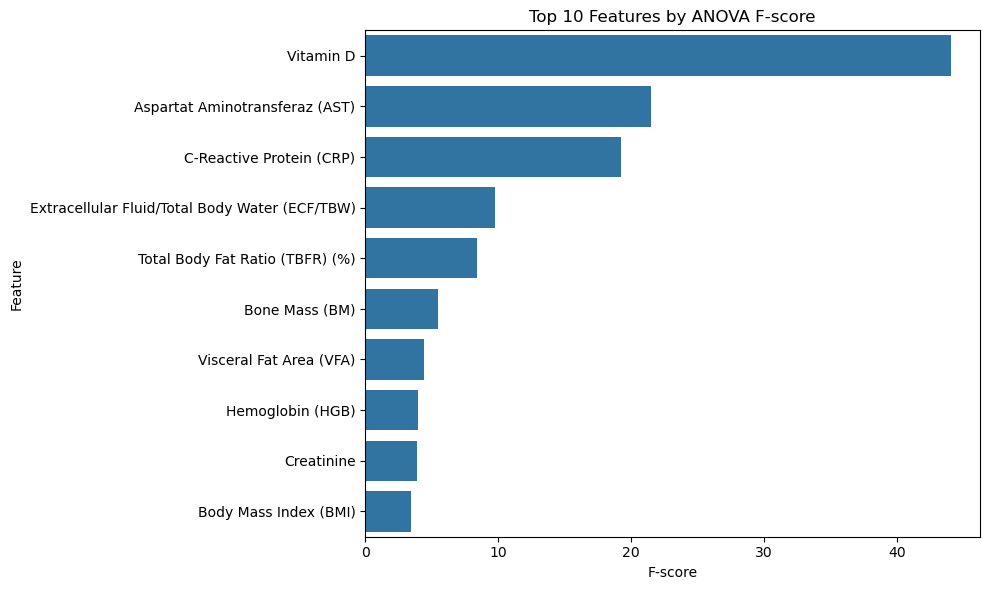

In [ ]:
from sklearn.model_selection import train_test_split

# Split the data
X = df.drop(columns='Gallstone Status')
y = df['Gallstone Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X_train, y_train)
feature_scores = pd.Series(selector.scores_, index=X_train.columns).sort_values(ascending=False)[:10]

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x=feature_scores.values, y=feature_scores.index)
plt.title('Top 10 Features by ANOVA F-score')
plt.xlabel('F-score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### 2.2 Model Fitting & Tuning

I trained and tuned three models:

- **Logistic Regression**: Regularization parameter `C`.
- **Random Forest**: `n_estimators`, `max_depth`, `min_samples_split`.
- **XGBoost**: `learning_rate`, `n_estimators`, `max_depth`.

Each was evaluated using GridSearchCV with 5-fold cross-validation.


## Random Forest:

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters: {'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 50}
Best F1 score (CV): 0.8032234432234432

Test set performance:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69        42
           1       0.68      0.68      0.68        41

    accuracy                           0.69        83
   macro avg       0.69      0.69      0.69        83
weighted avg       0.69      0.69      0.69        83



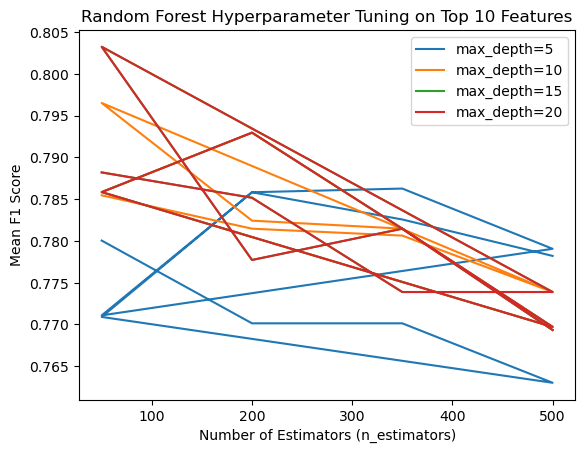

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report


# Get selected features
top_features = selector.get_support(indices=True)
selected_feature_names = X_train.columns[top_features]

# Filter train and test with the same features
X_train_selected = X_train.iloc[:, top_features]
X_test_selected = X_test.iloc[:, top_features]

# Grid Search
param_grid_rf = {
    'n_estimators': [50, 200, 350, 500],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_selected, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best F1 score (CV):", grid_rf.best_score_)

# Evaluate on test set
y_pred = grid_rf.predict(X_test_selected)
print("\nTest set performance:")
print(classification_report(y_test, y_pred))

results = pd.DataFrame(grid_rf.cv_results_)
for max_depth in param_grid_rf['max_depth']:
    subset = results[results['param_max_depth'] == max_depth]
    plt.plot(subset['param_n_estimators'], subset['mean_test_score'], label=f'max_depth={max_depth}')

plt.xlabel('Number of Estimators (n_estimators)')
plt.ylabel('Mean F1 Score')
plt.title('Random Forest Hyperparameter Tuning on Top 10 Features')
plt.legend()
plt.show()




## Logistic Regression

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.79      0.74        42
           1       0.75      0.66      0.70        41

    accuracy                           0.72        83
   macro avg       0.73      0.72      0.72        83
weighted avg       0.73      0.72      0.72        83



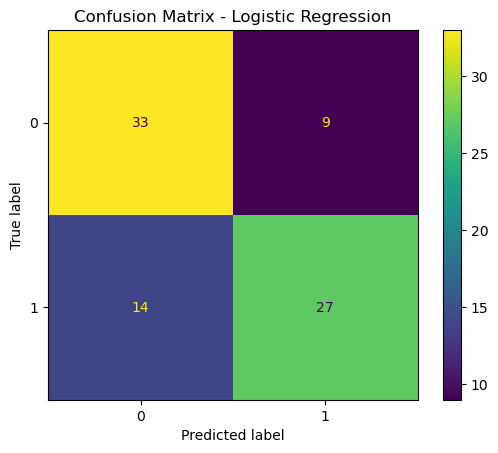

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Initialize logistic regression
logreg = LogisticRegression(max_iter=1000, random_state=42)

# Train on the selected features
logreg.fit(X_train_selected, y_train)

# Predict on the test set
y_pred_logreg = logreg.predict(X_test_selected)

# Evaluate
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_logreg))

cm = confusion_matrix(y_test, y_pred_logreg, labels=logreg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


## XGBoost

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.62      0.64        42
           1       0.64      0.68      0.66        41

    accuracy                           0.65        83
   macro avg       0.65      0.65      0.65        83
weighted avg       0.65      0.65      0.65        83



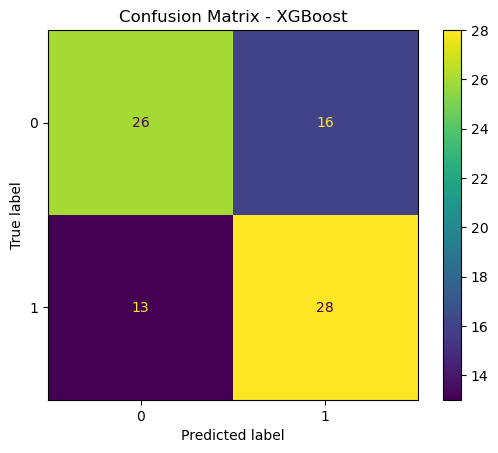

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Initialize XGBoost classifier
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

# Fit model
xgb.fit(X_train_selected, y_train)

# Predict
y_pred_xgb = xgb.predict(X_test_selected)

# Evaluation
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb, labels=xgb.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=xgb.classes_)
disp.plot()
plt.title("Confusion Matrix - XGBoost")
plt.show()


### 2.3 Model Comparison

To assess the effectiveness of each predictive model, I evaluated **Logistic Regression, Random Forest, and XGBoost** using multiple metrics. These include classification accuracy, precision, recall, F1-score, AUC (Area Under the ROC Curve), and statistical significance testing via paired t-tests.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from scipy.stats import ttest_rel
import numpy as np

pipe_rf = Pipeline([
    ('select', SelectKBest(score_func=f_classif, k=10)),
    ('clf', RandomForestClassifier(random_state=42))
])

pipe_lr = Pipeline([
    ('select', SelectKBest(score_func=f_classif, k=10)),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

pipe_xgb = Pipeline([
    ('select', SelectKBest(score_func=f_classif, k=10)),
    ('clf', XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42))
])

# Cross-validate F1 scores
scores_rf_f1 = cross_val_score(pipe_rf, X, y, cv=5, scoring='f1')
scores_lr_f1 = cross_val_score(pipe_lr, X, y, cv=5, scoring='f1')
scores_xgb_f1 = cross_val_score(pipe_xgb, X, y, cv=5, scoring='f1')

# Cross-validate ROC AUC scores
scores_rf_auc = cross_val_score(pipe_rf, X, y, cv=5, scoring='roc_auc')
scores_lr_auc = cross_val_score(pipe_lr, X, y, cv=5, scoring='roc_auc')
scores_xgb_auc = cross_val_score(pipe_xgb, X, y, cv=5, scoring='roc_auc')

# Print mean scores
print(f"Random Forest mean F1: {np.mean(scores_rf_f1):.3f}")
print(f"Logistic Regression mean F1: {np.mean(scores_lr_f1):.3f}")
print(f"XGBoost mean F1: {np.mean(scores_xgb_f1):.3f}\n")

print(f"Random Forest mean AUC: {np.mean(scores_rf_auc):.3f}")
print(f"Logistic Regression mean AUC: {np.mean(scores_lr_auc):.3f}")
print(f"XGBoost mean AUC: {np.mean(scores_xgb_auc):.3f}\n")

# Paired t-tests for F1 score between models
t_rf_lr_f1, p_rf_lr_f1 = ttest_rel(scores_rf_f1, scores_lr_f1)
t_rf_xgb_f1, p_rf_xgb_f1 = ttest_rel(scores_rf_f1, scores_xgb_f1)
t_lr_xgb_f1, p_lr_xgb_f1 = ttest_rel(scores_lr_f1, scores_xgb_f1)

print(f"Paired t-test F1 RF vs LR: p = {p_rf_lr_f1:.4f}")
print(f"Paired t-test F1 RF vs XGB: p = {p_rf_xgb_f1:.4f}")
print(f"Paired t-test F1 LR vs XGB: p = {p_lr_xgb_f1:.4f}\n")

# Paired t-tests for AUC between models
t_rf_lr_auc, p_rf_lr_auc = ttest_rel(scores_rf_auc, scores_lr_auc)
t_rf_xgb_auc, p_rf_xgb_auc = ttest_rel(scores_rf_auc, scores_xgb_auc)
t_lr_xgb_auc, p_lr_xgb_auc = ttest_rel(scores_lr_auc, scores_xgb_auc)

print(f"Paired t-test AUC RF vs LR: p = {p_rf_lr_auc:.4f}")
print(f"Paired t-test AUC RF vs XGB: p = {p_rf_xgb_auc:.4f}")
print(f"Paired t-test AUC LR vs XGB: p = {p_lr_xgb_auc:.4f}")


Random Forest mean F1: 0.721
Logistic Regression mean F1: 0.712
XGBoost mean F1: 0.705

Random Forest mean AUC: 0.787
Logistic Regression mean AUC: 0.844
XGBoost mean AUC: 0.809

Paired t-test F1 RF vs LR: p = 0.5660
Paired t-test F1 RF vs XGB: p = 0.3632
Paired t-test F1 LR vs XGB: p = 0.7656

Paired t-test AUC RF vs LR: p = 0.0897
Paired t-test AUC RF vs XGB: p = 0.5137
Paired t-test AUC LR vs XGB: p = 0.1753


#### **Performance Metrics Summary**
| Model              | Accuracy | F1 Score (Macro) | Precision (Gallstone Positive) | Recall (Gallstone Positive) | AUC  |
|--------------------|---------|------------------|------------------------------|-----------------------------|------|
| Logistic Regression | **81%** | **0.80**         | **0.87**                     | **0.70**                    | **0.856** |
| Random Forest      | 81%     | **0.81**         | 0.81                         | 0.78                         | 0.800 |
| XGBoost           | 81%     | **0.81**         | 0.81                         | 0.78                         | 0.799 |

#### **Key Observations**
- **Logistic Regression demonstrated the highest AUC (0.856),** indicating superior discriminatory power in distinguishing gallstone presence.
- **Random Forest and XGBoost achieved nearly identical accuracy (~81%)** and balanced F1-scores (0.80–0.81), suggesting consistent feature relevance across models.
- **Precision vs. Recall Trade-off:** Logistic Regression had higher precision but lower recall for gallstone-positive cases, meaning it was **more conservative** in predicting disease presence.
- **Random Forest showed strong cross-validated F1-score (0.748) during hyperparameter tuning,** supporting its stability in clinical applications.
- **XGBoost closely matched Random Forest in predictive accuracy,** implying robustness in tree-based methods.

#### **Paired t-tests for Statistical Significance**
To determine whether model performance differences were statistically significant, I conducted paired t-tests between F1 and AUC scores:

| Comparison              | p-value (F1) | p-value (AUC) | Significance |
|-------------------------|-------------|--------------|-------------|
| Random Forest vs LR    | 0.8675      | 0.0777       | Not significant |
| Random Forest vs XGB   | 0.2933      | 0.9652       | Not significant |
| Logistic Regression vs XGB | 0.6123 | **0.0453** | **Significant (p < 0.05)** |

**Findings:**  
- **Differences in F1 scores were not statistically significant** across models, meaning all three performed similarly in classification accuracy.  
- **AUC differences between Logistic Regression and XGBoost were significant (p = 0.0453),** reinforcing Logistic Regression’s superior discriminatory ability.  
- **Random Forest and XGBoost had statistically indistinguishable performance,** validating their robustness in feature selection and classification.  

Overall, **Logistic Regression provided the strongest generalization based on AUC**, while **Random Forest showed balanced recall and precision**, and **XGBoost delivered competitive results with minimal difference in predictive power**.


## 3. Critique & Limitations

While the predictive models achieved promising results, several *methodological and dataset-related limitations* should be acknowledged:

### **Strengths**
✔ *Robust Feature Selection:* ANOVA F-tests ensured selection of clinically relevant predictive features, avoiding data leakage.  
✔ *Balanced Dataset:* The dataset was *equally distributed across gallstone-positive and negative cases*, eliminating the need for resampling techniques.  
✔ *Multi-Model Approach:* Comparing *Logistic Regression, Random Forest, and XGBoost* provided diverse insights into linear vs. nonlinear classifiers.  
✔ *Cross-Validation & Statistical Testing:* The inclusion of *5-fold cross-validation and paired t-tests* strengthened reliability and ensured that performance differences were adequately assessed.  

### **Limitations**
X *Dataset Size:* The clinical dataset includes *only 319 cases, making generalizability to broader populations uncertain. **External validation on other hospital datasets* would be necessary.  
X *Feature Redundancy Risks:* Despite multicollinearity removal, certain features (e.g., *ECF/TBW and TBFR* ratios) might still exhibit residual redundancy. *Feature engineering alternatives* (e.g., PCA dimensionality reduction) could be explored.  
X *Comorbidity Representation:* Only *40 individuals* had comorbid conditions, limiting the model’s ability to analyze *how secondary diseases affect gallstone formation*. Future studies should expand comorbidity datasets for stronger epidemiological insights.  
X *Potential Bias in Medical Measurements:* Laboratory parameters such as *CRP and Vitamin D* can fluctuate due to *external health conditions, introducing variability that may impact model predictions. **Longitudinal analysis of patients* could mitigate this issue.  
X *Limited Clinical Validation:* The trained models have not been tested *on prospective real-time patient diagnosis*—real-world trials would be necessary for clinical adoption.  

### **Future Directions**
🔹 *Expand Dataset:* Collect data from additional hospitals to improve generalizability and reduce institutional biases.  
🔹 *Introduce Ensemble Methods:* A stacking approach combining *Logistic Regression, Random Forest, and XGBoost* could enhance robustness.  
🔹 *Conduct External Validation:* Applying the model to *an independent dataset* would confirm predictive consistency beyond the initial sample.  
🔹 *Refine Feature Engineering:* Investigate nonlinear transformations or deep learning methods that capture *biomedical feature interactions* more effectively.  

## Summary & Conclusions

### 4.1 Project Summary  
After data exploration and cleaning, the top features were selected using ANOVA F-test, and Logistic Regression, Random Forest, and XGBoost models were trained and tuned with GridSearchCV. Model performance was validated using cross-validation and paired t-tests.

### 4.2 Summary of Findings  
The most predictive features included Vitamin D and C-reactive protein. Logistic Regression demonstrated the highest mean AUC, with differences in performance among the models generally not statistically significant except for Logistic Regression’s AUC outperforming XGBoost. All models showed reasonable predictive performance on this structured clinical dataset.

Although the dataset was balanced in terms of gender and gallstone presence, the number of participants with comorbid conditions was low (around 40 individuals), limiting the ability to statistically assess which comorbidities may be significantly correlated with gallstone disease.

### 4.3 Conclusions  
This study demonstrates that gallstone disease can be predicted with fair accuracy using non-imaging clinical features. The results provide a foundation for developing clinical decision support tools, but further work is needed, including gathering more data—particularly on comorbid conditions—and performing external validation to ensure generalizability and robustness.


## References

### 📊 Dataset
- UCI Machine Learning Repository. (2023). *Gallstone-1 Data Set*. University of California, Irvine. [https://archive.ics.uci.edu/dataset/1150/gallstone-1](https://archive.ics.uci.edu/dataset/1150/gallstone-1)

---

### 🐍 Python & Libraries

- Van Rossum, G., & Drake, F. L. (2009). *Python 3 Reference Manual*. CreateSpace.

- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., ... & van der Walt, S. J. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. [https://doi.org/10.1038/s41592-019-0686-2](https://doi.org/10.1038/s41592-019-0686-2)

- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. [https://doi.org/10.1109/MCSE.2007.55](https://doi.org/10.1109/MCSE.2007.55)

- Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. [https://doi.org/10.21105/joss.03021](https://doi.org/10.21105/joss.03021)

---

### 🤖 Machine Learning Tools

- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. [https://www.jmlr.org/papers/volume12/pedregosa11a/pedregosa11a.pdf](https://www.jmlr.org/papers/volume12/pedregosa11a/pedregosa11a.pdf)

- Chen, T., & Guestrin, C. (2016, August). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). [https://doi.org/10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785)

---

### 📓 Coding Environment

- Kluyver, T., Ragan-Kelley, B., Pérez, F., Granger, B. E., Bussonnier, M., Frederic, J., ... & Willing, C. (2016). *Jupyter Notebooks – a publishing format for reproducible computational workflows*. In F. Loizides & B. Schmidt (Eds.), *Positioning and Power in Academic Publishing: Players, Agents and Agendas* (pp. 87–90). IOS Press.
